# Frozen pretrained encoders + probes vs CNNs trained from scratch

**Question.** Do general-purpose visual features carry information about the next 5–60 minutes that the image CNN
trained from scratch does not find? The encoder is **frozen** (never trained); only a small head (the *probe*) is fit on
its features. This is the cheap version of the scratch-versus-pretrained comparison.

**Same data as `AllData_AllModel.ipynb`** (`run_20261116_044159`): 2016–2025 five-minute charts of the S&P 500 ∪ NASDAQ 100
∪ DJIA members, rendered on the fly from point-in-time windows (234×234, exactly the image the CNN saw), split train
2016–2022 · validation 2023 · test 2024–2025 (section 9, run once at the end). Targets `vol`, `xsdir`, `dir` at 5 / 15 / 30 /
60 minutes, one window per stock per hour (stride 12).

| group | model | what it answers |
|---|---|---|
| probes | **DINOv2 ViT-S/14 frozen + linear probe** (logistic regression) | the core experiment |
| | DINOv2 frozen + 2-layer MLP probe | does a more expressive head help? |
| | CLIP ViT-B/16 frozen + the same probes | is it specific to DINO? |
| | each probe also with SPY's chart features appended | same SPY question as before |
| floor | **random ViT-S/14** (DINOv2 architecture, untrained, frozen) + the same probes | does *pretraining* matter, or just a big random projection? |
| | training prior (majority) | AUC 0.5 |
| reference | image CNN, image CNN + SPY, 1D CNN, HGB, HGB + SPY | **loaded** from `runs/run_20261116_044159`, not retrained |

Every model is scored on **identical validation rows**: the probes' predictions are joined row by row with the saved
predictions of the reference run.

**Leakage controls** (Boyang's points):
- **Purge.** A label is kept only if its whole horizon ends inside its own split (`chartcnn.build_split`); labels are
  intraday, so no label crosses a split boundary.
- **Embargo.** An input window is 78 bars, exactly one session, so windows of the first session after a boundary still
  contain bars of the session before it. `embargo_sessions` whole sessions are removed on **both sides** of every boundary
  (train | validation and validation | test), so no input or label overlaps across splits, with a gap to spare.
- **Preprocessing fit on train only.** The `vol` threshold (each stock's median |return|) and the probes' feature
  standardisation (mean, std) are computed from training rows only and applied unchanged to validation and test.
  Encoders are frozen with their published statistics. Probe hyper-parameters (L2 strength, weight decay, epochs) are
  chosen on validation days, as the CNNs' early stopping was; the test period is never used.

**Advisor rule.** Every model prints its parameter count: the encoder's (all frozen, 0 trainable) and the probe's
(trainable) separately.

**Resumable**: features are saved to Drive in chunks and finished cells are skipped; after a disconnect set `RUN_ID`
and Run all.

## 1. Setup
Copies the data bundle (1.2 GB) from Drive to the Colab disk and unzips it (4.5 GB); a few minutes.

In [8]:
import os, sys, json, shutil, tempfile, zipfile, hashlib, time
from pathlib import Path

LOCAL_TEST = os.environ.get("ALLDATA_LOCAL_NOTEBOOK_TEST") == "1"     # repository QA only
if LOCAL_TEST:
    HERE = Path(os.environ["ALLDATA_LOCAL_HERE"])
else:
    from google.colab import drive
    drive.mount("/content/drive")
    HERE = Path("/content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/AllData & AllModel")
BUNDLE = HERE / "alldata_bundle_v1.zip"
assert BUNDLE.is_file(), f"Put alldata_bundle_v1.zip in {HERE}"
assert (HERE / "frozen_probe.py").is_file(), f"Put frozen_probe.py in {HERE}"

LOCAL = Path(tempfile.mkdtemp(prefix="probe_", dir=None if LOCAL_TEST else "/content"))
STAGE = LOCAL / "bundle"
STAGE.mkdir(parents=True)
shutil.copy2(BUNDLE, LOCAL / "bundle.zip")
with zipfile.ZipFile(LOCAL / "bundle.zip") as z:
    for info in z.infolist():                       # refuse paths escaping the folder
        assert (STAGE / info.filename).resolve().is_relative_to(STAGE.resolve())
    z.extractall(STAGE)
(LOCAL / "bundle.zip").unlink()
def _sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 24), b""): h.update(b)
    return h.hexdigest()
for rel, d in json.loads((STAGE / "bundle_manifest.json").read_text())["files"].items():
    assert _sha(STAGE / rel) == d["sha256"], f"checksum mismatch: {rel}"
PREPARED = STAGE / "prepared"

# chartcnn/ next to this notebook on Drive wins (easy to edit); otherwise the copy inside the bundle.
CODE = HERE if (HERE / "chartcnn").is_dir() else STAGE
sys.path[:0] = [str(HERE), str(CODE)]
import numpy as np, pandas as pd, torch
from IPython.display import display, Markdown
import chartcnn
import frozen_probe as fp
assert chartcnn.__version__ >= "2026-11-16.1", f"stale chartcnn {chartcnn.__version__} in {CODE}"
print("frozen_probe", fp.__version__)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("data:", PREPARED, "| code:", CODE, "| device:", DEVICE, torch.cuda.get_device_name() if DEVICE.type == "cuda" else "")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
frozen_probe 2026-11-17.1
data: /content/probe_ui7803d9/bundle/prepared | code: /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/AllData & AllModel | device: cuda NVIDIA L4


## 2. Configuration
Change settings here only. **To resume after a disconnect**, set `RUN_ID` to the id printed by the first run and Run all again.

`QUICK = True` is a small first pass (40,000 training windows, every 5th validation day, 60 and 5 minutes, DINOv2 and
the random encoder only), about 20–30 minutes on an L4, to check everything runs; its numbers are rough.

**Time on an L4 (estimate, not measured on this data).** The full run renders ~300,000 training and ~570,000 validation
charts once and feeds each to every encoder: roughly 20–40 minutes for DINOv2-S + random ViT-S, plus 30–60 minutes for
CLIP ViT-B/16. Chart drawing runs on the CPU, so more CPU cores (High-RAM runtime) help. The probes then take 1–3 minutes
per cell, about 30 minutes for all 12 cells. Features are cached on Drive (float16, about 5 GB for the full run), so a
rerun or a new probe does not redo the encoders.

In [9]:
from datetime import datetime, timezone
SMOKE = LOCAL_TEST                                 # tiny code check with untrained tiny encoders; never a result
assert DEVICE.type == "cuda" or SMOKE, "Select a GPU runtime"

RUN_ID = None                                      # None = new run; or an old RUN_ID to resume it
QUICK = False
REFERENCE_RUN = "run_20261116_044159"              # AllData & AllModel run whose CNN/HGB scores are compared
ENCODER_NAMES = ["dinov2_s", "dinov2_s_random", "clip_b16"]   # add "dinov2_b" for DINOv2 ViT-B/14
PROBES = ["linear", "mlp"]
SETTINGS = dict(
    stride=12, embargo_sessions=2,                 # sessions removed on each side of each split boundary
    max_train_windows=300_000,                     # same training budget as the CNNs (max_train_nn)
    validation_every_kth_day=1,                    # 1 = all of 2023
    early_stop_every_kth_day=4,                    # probe selection on every 4th validation day, as for the CNNs
    extract_batch=256, chunk=50_000, amp=True,     # bfloat16 encoders on L4/A100
    num_workers=0 if SMOKE else min(12, os.cpu_count() or 2),
    probe_lr=1e-3, probe_batch=4096, probe_epochs=30, probe_patience=3,
    linear_l2_grid=[1e-5, 1e-4, 1e-3],             # logistic regression ridge penalty, picked on validation days
    mlp_hidden=512, mlp_dropout=0.2, mlp_weight_decay_grid=[1e-2, 1e-1],
    seed=69,
)
HORIZONS = [12, 1, 6, 3]                           # bars of 5 minutes: 60, 5, 30, 15 minutes (run order)
KINDS = ["vol", "xsdir", "dir"]
if QUICK:
    SETTINGS.update(max_train_windows=40_000, validation_every_kth_day=5)
    HORIZONS, ENCODER_NAMES = [12, 1], ["dinov2_s", "dinov2_s_random"]
if SMOKE:
    SETTINGS.update(max_train_windows=300, extract_batch=16, chunk=128, probe_epochs=3, probe_batch=64,
                    embargo_sessions=1, early_stop_every_kth_day=1, linear_l2_grid=[1e-4], mlp_weight_decay_grid=[1e-2])
    HORIZONS = [12, 1]
CELLS = [dict(name=f"{k}_h{h}", kind=k, target=fp.KINDS[k], horizon=h, minutes=5 * h, stride=SETTINGS["stride"])
         for h in HORIZONS for k in KINDS]

RESUME = RUN_ID is not None
RUN_ID = RUN_ID or ("local_smoke" if LOCAL_TEST else datetime.now(timezone.utc).strftime("probe_%Y%m%d_%H%M%S"))
RUN_DRIVE, RUN_LOCAL = HERE / "probe_runs" / RUN_ID, LOCAL / "run"
if RESUME:
    assert RUN_DRIVE.exists(), f"{RUN_DRIVE} not found"
else:
    assert LOCAL_TEST or not RUN_DRIVE.exists(), "RUN_ID exists: set RUN_ID to resume it"
RUN_DRIVE.mkdir(parents=True, exist_ok=True); RUN_LOCAL.mkdir(parents=True, exist_ok=True)
(RUN_DRIVE / ("settings_resume.json" if RESUME else "settings.json")).write_text(json.dumps(dict(
    settings=SETTINGS, encoders=ENCODER_NAMES, probes=PROBES, cells=CELLS, quick=QUICK, reference=REFERENCE_RUN,
    chartcnn=chartcnn.__version__, frozen_probe=fp.__version__), indent=2))
REF_DIR = HERE / "runs" / REFERENCE_RUN
print("RUN_ID:", RUN_ID, "->", RUN_DRIVE)
print("reference run found:", REF_DIR.is_dir(), REF_DIR)
print(len(CELLS), "cells:", ", ".join(c["name"] for c in CELLS))

RUN_ID: probe_20261118_031436 -> /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/AllData & AllModel/probe_runs/probe_20261118_031436
reference run found: True /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/AllData & AllModel/runs/run_20261116_044159
12 cells: vol_h12, xsdir_h12, dir_h12, vol_h1, xsdir_h1, dir_h1, vol_h6, xsdir_h6, dir_h6, vol_h3, xsdir_h3, dir_h3


## 3. Windows, purge and embargo
One fixed set of windows per split, shared by every cell, encoder and probe (saved on Drive so a resume uses the same rows).
The checks below fail loudly if any validation input reaches back into the training period or any training label ends
after it.

In [ ]:
store = chartcnn.Store(PREPARED)
cfg = store.config
EMBARGO = fp.embargo_dates(store, SETTINGS["embargo_sessions"])
days = fp.sessions(store)
for b in (cfg["train_end"], cfg["validation_end"]):
    k = np.searchsorted(days, b, side="right")
    print(f"boundary after {b}: embargoed sessions", [d for d in days[max(0, k - 3):k + 3] if d in EMBARGO])

W = {}
for split, kw in (("train", dict(max_rows=SETTINGS["max_train_windows"])),
                  ("valid", dict(every_kth_day=SETTINGS["validation_every_kth_day"]))):
    path = RUN_DRIVE / f"windows_{split}.parquet"
    if path.exists():
        W[split] = pd.read_parquet(path)
    else:
        W[split] = fp.decision_windows(store, "train" if split == "train" else "validation", SETTINGS["stride"],
                                       EMBARGO, seed=SETTINGS["seed"], **kw)
        W[split].to_parquet(path, index=False)

# Leakage checks (inputs and labels never cross a split boundary)
first_valid_input = store.dates[W["valid"].end_index.min() - fp.LOOKBACK + 1]
last_train_label = store.dates[W["train"].end_index.max() + max(HORIZONS)]
assert first_valid_input > cfg["train_end"], "a validation input window reaches into the training period"
assert last_train_label <= cfg["train_end"], "a training label ends after the training period"
print(f"train windows {len(W['train']):,} ({W['train'].decision_date.min()} – {W['train'].decision_date.max()}), "
      f"last training label bar on {last_train_label}")
print(f"validation windows {len(W['valid']):,} ({W['valid'].decision_date.min()} – {W['valid'].decision_date.max()}, "
      f"{W['valid'].decision_date.nunique()} days), first validation input bar on {first_valid_input}")

# SPY's chart depends only on the time slot: encode it once per slot.
SLOTS = np.unique(np.concatenate([W["train"].end_index, W["valid"].end_index]))
SLOT_POS = np.full(store.T, -1, np.int64); SLOT_POS[SLOTS] = np.arange(len(SLOTS))
print(f"distinct SPY slots: {len(SLOTS):,}")

## 4. Encoders and what they see
Each encoder prints its parameter count (all frozen). The chart is resized from 234×234 to 224×224, copied to three
channels and normalised with the encoder's own pretraining statistics; the feature is the CLS token next to the mean of
the patch tokens.

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

dinov2_s = DINOv2 ViT-S/14: 22,056,576 parameters (0 trainable, frozen), feature size 768 (CLS + mean patch)
dinov2_s_random = random ViT-S/14 (DINOv2 architecture, untrained): 22,056,576 parameters (0 trainable, frozen), feature size 768 (CLS + mean patch)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] CLIPVisionModel LOAD REPORT from: openai/clip-vit-base-patch16
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1

clip_b16 = CLIP ViT-B/16: 85,799,424 parameters (0 trainable, frozen), feature size 1536 (CLS + mean patch)


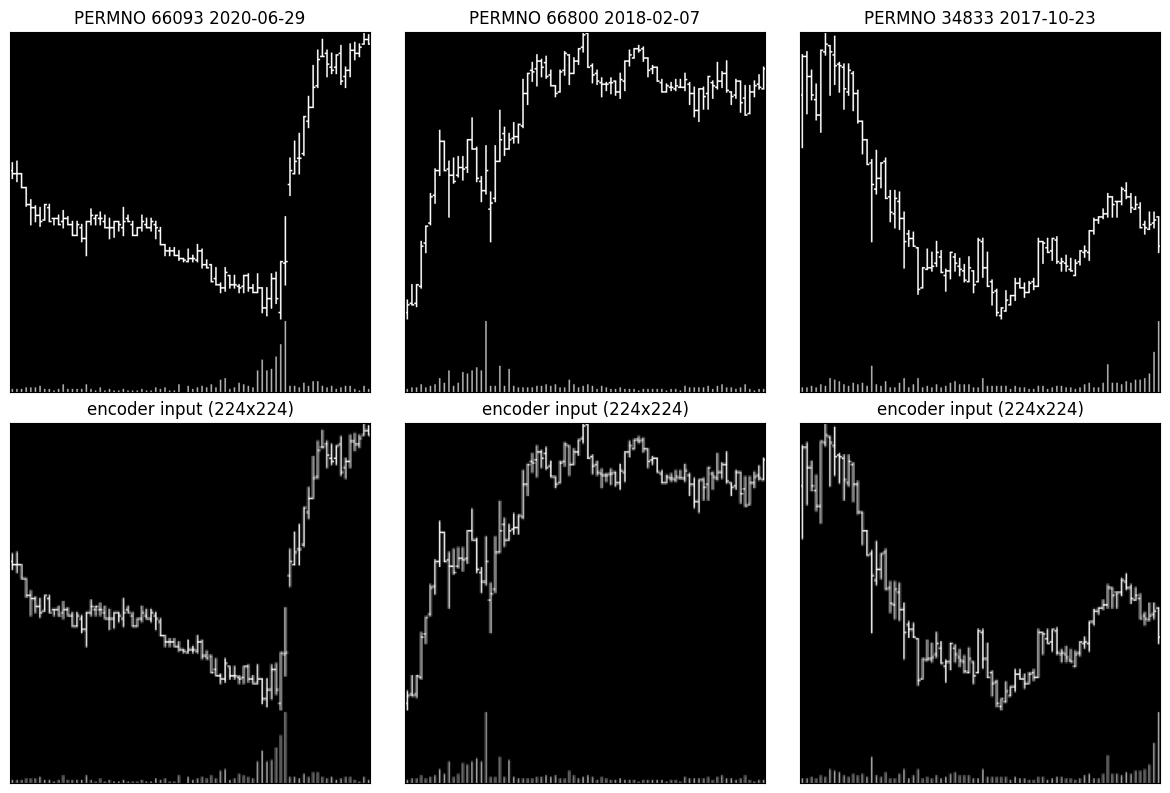

In [ ]:
import matplotlib.pyplot as plt
ENCODERS = fp.build_encoders(ENCODER_NAMES, DEVICE, tiny=SMOKE, seed=SETTINGS["seed"])
ENCODER_PARAMS = {e: enc.parameters_count()[0] for e, enc in ENCODERS.items()}
example = W["train"].sample(3, random_state=1).reset_index(drop=True)
charts = fp.StockCharts(PREPARED, example)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i in range(3):
    img = charts[i]
    axes[0, i].imshow(img, cmap="gray"); axes[0, i].set_title(f"PERMNO {example.permno[i]} {example.decision_date[i]}")
    small = torch.nn.functional.interpolate(img[None, None].float(), size=(224, 224), mode="bilinear", antialias=True)[0, 0]
    axes[1, i].imshow(small, cmap="gray"); axes[1, i].set_title("encoder input (224x224)")
    for ax in axes[:, i]: ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); plt.show()

## 5. Extract features (once, cached on Drive)
Each chart is drawn once and passed through every encoder. Saved per chunk to `probe_runs/<RUN_ID>/features/`; a rerun
skips finished chunks.

In [ ]:
FEAT_LOCAL, FEAT_DRIVE = LOCAL / "features", RUN_DRIVE / "features"
FEATS = {e: {} for e in ENCODER_NAMES}
kw = dict(batch_size=SETTINGS["extract_batch"], workers=SETTINGS["num_workers"], chunk=SETTINGS["chunk"],
          amp=SETTINGS["amp"], drive_dir=None)
t0 = time.perf_counter()
for split in ("train", "valid"):
    out = fp.extract(fp.StockCharts(PREPARED, W[split]), ENCODERS, FEAT_LOCAL, split, DEVICE, **kw)
    for e in out: FEATS[e][split] = out[e]
SPY = fp.extract(fp.SpyCharts(PREPARED, SLOTS), ENCODERS, FEAT_LOCAL, "spy", DEVICE, **kw)
print(f"features ready in {(time.perf_counter() - t0) / 60:.1f} min:",
      {e: {s: FEATS[e][s].shape for s in FEATS[e]} for e in FEATS}, "SPY", {e: SPY[e].shape for e in SPY})
del ENCODERS
if DEVICE.type == "cuda": torch.cuda.empty_cache()

  train: chunk 1/6 (50,000/300,000 charts, ~299 charts/s this session)
  train: chunk 2/6 (100,000/300,000 charts, ~299 charts/s this session)
  train: chunk 3/6 (150,000/300,000 charts, ~300 charts/s this session)
  train: chunk 4/6 (200,000/300,000 charts, ~300 charts/s this session)
  train: chunk 5/6 (250,000/300,000 charts, ~300 charts/s this session)
  train: chunk 6/6 (300,000/300,000 charts, ~300 charts/s this session)
  valid: chunk 1/12 (50,000/577,755 charts, ~300 charts/s this session)
  valid: chunk 2/12 (100,000/577,755 charts, ~300 charts/s this session)
  valid: chunk 3/12 (150,000/577,755 charts, ~300 charts/s this session)
  valid: chunk 4/12 (200,000/577,755 charts, ~300 charts/s this session)
  valid: chunk 5/12 (250,000/577,755 charts, ~300 charts/s this session)
  valid: chunk 6/12 (300,000/577,755 charts, ~300 charts/s this session)
  valid: chunk 7/12 (350,000/577,755 charts, ~300 charts/s this session)
  valid: chunk 8/12 (400,000/577,755 charts, ~300 charts/s 

## 6. Fit the probes (validation 2023)
Per cell and encoder: linear and MLP probe on the stock's features, then the same with SPY's features appended. Each line
prints the probe's trainable parameters, the chosen regularisation and the validation AUC.

In [ ]:
RESULTS, t0 = {}, time.perf_counter()
for i, cell in enumerate(CELLS, 1):
    print("\n" + "=" * 20, f"[{i}/{len(CELLS)}]", cell["name"], "=" * 20)
    tr, median = fp.cell_rows(store, cell, "train", W["train"])
    va, _ = fp.cell_rows(store, cell, "validation", W["valid"], median)       # vol threshold from train only
    assert (store.dates[tr.end_index + cell["horizon"]] <= cfg["train_end"]).all()          # purge
    assert (store.dates[va.end_index + cell["horizon"]] <= cfg["validation_end"]).all()
    data = dict(train=tr, valid=va, feats=FEATS, spy=SPY, slot_pos=SLOT_POS)
    RESULTS[cell["name"]] = fp.run_cell(cell, data, ENCODER_NAMES, PROBES, SETTINGS, DEVICE,
                                        RUN_LOCAL / cell["name"], RUN_DRIVE / cell["name"], smoke=SMOKE)
    if cell["target"] == "vol":
        median.to_csv(RUN_LOCAL / cell["name"] / "train_abs_return_median.csv")
        shutil.copy2(RUN_LOCAL / cell["name"] / "train_abs_return_median.csv", RUN_DRIVE / cell["name"])
    print(f"elapsed {(time.perf_counter() - t0) / 60:.1f} min")


==================== [1/12] vol_h12 ====================
vol_h12 (volatility, next 60 min): 296,814 train / 563,762 validation rows (141,435 on early-stopping days); positive share 0.501 / 0.489
  dinov2_s_linear                        769 trainable probe params | reg 0.0001 | best epoch 4 | val AUC 0.6379
  dinov2_s_mlp                       394,241 trainable probe params | reg 0.1 | best epoch 7 | val AUC 0.6421
  dinov2_s_spy_linear                  1,537 trainable probe params | reg 0.001 | best epoch 4 | val AUC 0.6448
  dinov2_s_spy_mlp                   787,457 trainable probe params | reg 0.01 | best epoch 2 | val AUC 0.6450
  dinov2_s_random_linear                 769 trainable probe params | reg 1e-05 | best epoch 7 | val AUC 0.5944
  dinov2_s_random_mlp                394,241 trainable probe params | reg 0.01 | best epoch 7 | val AUC 0.6004
  dinov2_s_random_spy_linear           1,537 trainable probe params | reg 1e-05 | best epoch 1 | val AUC 0.5998
  dinov2_s_random_spy_m

## 7. Compare with the CNNs, HGB and the random encoder
The reference scores of `run_20261116_044159` are joined on (stock, decision bar). Only rows present in both are kept,
so every number below is on identical rows (the embargo removes the first and last two sessions of 2023).
AUC with 95% intervals from resampling whole validation days; *paired* comparisons use the same resampled days for both
models.

vol_h12: 563,762 rows, 100.0% of probe rows matched in the reference run
xsdir_h12: 568,316 rows, 100.0% of probe rows matched in the reference run
dir_h12: 561,923 rows, 100.0% of probe rows matched in the reference run
vol_h1: 571,463 rows, 100.0% of probe rows matched in the reference run
xsdir_h1: 573,090 rows, 100.0% of probe rows matched in the reference run
dir_h1: 550,954 rows, 100.0% of probe rows matched in the reference run
vol_h6: 568,354 rows, 100.0% of probe rows matched in the reference run
xsdir_h6: 572,641 rows, 100.0% of probe rows matched in the reference run
dir_h6: 562,679 rows, 100.0% of probe rows matched in the reference run
vol_h3: 570,113 rows, 100.0% of probe rows matched in the reference run
xsdir_h3: 573,913 rows, 100.0% of probe rows matched in the reference run
dir_h3: 560,509 rows, 100.0% of probe rows matched in the reference run
Parameters (HGB: tree nodes of the first cell; probes: trainable head only, encoder frozen):


,frozen_encoder,trainable,total
model,,,
DINOv2-S linear probe,22056576,769,22057345
DINOv2-S MLP probe,22056576,394241,22450817
DINOv2-S + SPY linear probe,22056576,1537,22058113
DINOv2-S + SPY MLP probe,22056576,787457,22844033
random ViT-S linear probe,22056576,769,22057345
random ViT-S MLP probe,22056576,394241,22450817
random ViT-S + SPY linear probe,22056576,1537,22058113
random ViT-S + SPY MLP probe,22056576,787457,22844033
CLIP-B/16 linear probe,85799424,1537,85800961


DINOv2-S linear probe


,5 min,15 min,30 min,60 min
kind,,,,
dir,"0.502 [0.498, 0.508]","0.501 [0.494, 0.507]","0.495 [0.489, 0.500]","0.502 [0.495, 0.507]"
vol,"0.647 [0.640, 0.655]","0.635 [0.627, 0.642]","0.628 [0.620, 0.635]","0.638 [0.632, 0.643]"
xsdir,"0.502 [0.499, 0.504]","0.500 [0.498, 0.502]","0.501 [0.499, 0.503]","0.499 [0.497, 0.501]"


DINOv2-S MLP probe


,5 min,15 min,30 min,60 min
kind,,,,
dir,"0.501 [0.494, 0.508]","0.504 [0.500, 0.509]","0.498 [0.493, 0.503]","0.500 [0.496, 0.504]"
vol,"0.652 [0.644, 0.659]","0.639 [0.631, 0.646]","0.629 [0.622, 0.636]","0.642 [0.636, 0.647]"
xsdir,"0.502 [0.500, 0.504]","0.501 [0.500, 0.503]","0.500 [0.498, 0.502]","0.499 [0.497, 0.501]"


... (14 outputs left out)

1D CNN (scratch)


,5 min,15 min,30 min,60 min
kind,,,,
dir,"0.503 [0.496, 0.511]","0.502 [0.493, 0.510]","0.495 [0.487, 0.502]","0.505 [0.498, 0.512]"
vol,"0.658 [0.649, 0.665]","0.640 [0.632, 0.648]","0.632 [0.624, 0.640]","0.650 [0.643, 0.655]"
xsdir,"0.511 [0.508, 0.513]","0.503 [0.501, 0.506]","0.503 [0.501, 0.505]","0.502 [0.499, 0.505]"


HGB hand features


,5 min,15 min,30 min,60 min
kind,,,,
dir,"0.507 [0.500, 0.514]","0.500 [0.493, 0.507]","0.501 [0.493, 0.507]","0.506 [0.499, 0.513]"
vol,"0.683 [0.674, 0.690]","0.664 [0.656, 0.671]","0.658 [0.649, 0.665]","0.671 [0.665, 0.676]"
xsdir,"0.517 [0.515, 0.520]","0.511 [0.508, 0.513]","0.509 [0.507, 0.512]","0.506 [0.503, 0.508]"


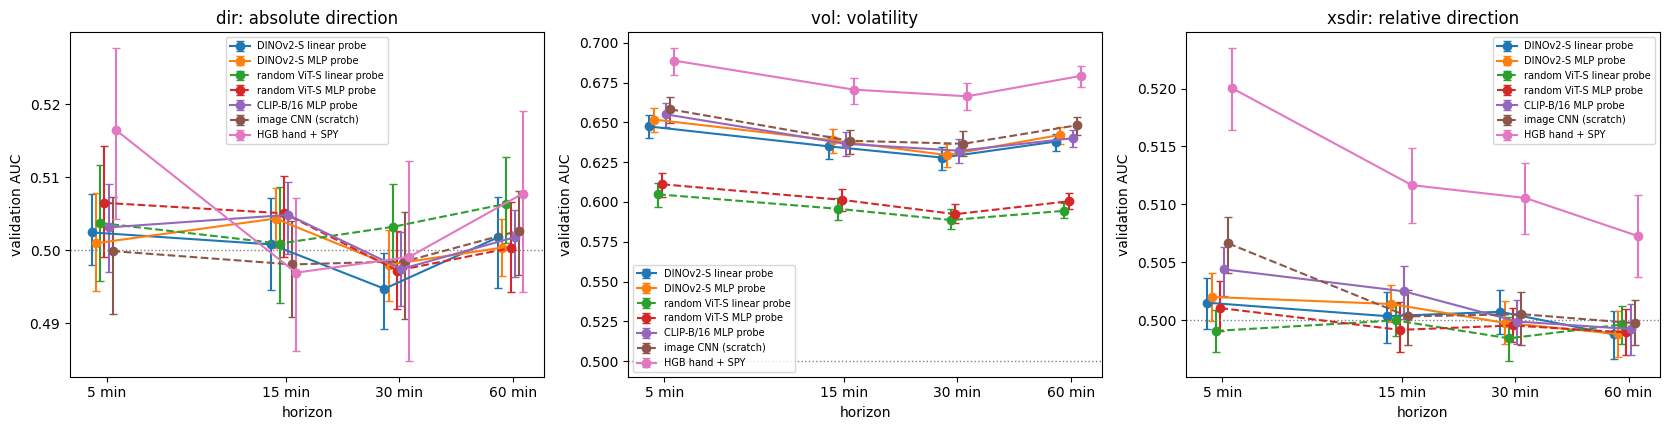

- **dir**: best model by horizon 5 min 0.516 (HGB hand + SPY), 15 min 0.505 (random ViT-S MLP probe), 30 min 0.503 (random ViT-S linear probe), 60 min 0.508 (random ViT-S + SPY linear probe).
- **vol**: best model by horizon 5 min 0.689 (HGB hand + SPY), 15 min 0.671 (HGB hand + SPY), 30 min 0.666 (HGB hand + SPY), 60 min 0.679 (HGB hand + SPY).
- **xsdir**: best model by horizon 5 min 0.520 (HGB hand + SPY), 15 min 0.512 (HGB hand + SPY), 30 min 0.511 (HGB hand + SPY), 60 min 0.507 (HGB hand + SPY).
- pretrained vs random encoder, linear probe (DINOv2-S linear probe − random ViT-S linear probe), paired day bootstrap over 12 cells: better in 5, worse in 1, tied in 6; mean AUC difference +0.0127.
- pretrained vs random encoder, MLP probe (DINOv2-S MLP probe − random ViT-S MLP probe), paired day bootstrap over 12 cells: better in 4, worse in 0, tied in 8; mean AUC difference +0.0128.
- MLP probe vs linear probe (DINOv2-S MLP probe − DINOv2-S linear probe), paired day bootstrap over 12 cells: better in 4, worse in 0, tied in 8; mean AUC difference +0.0016.
- frozen linear probe vs image CNN from scratch (DINOv2-S linear probe − image CNN (scratch)), paired day bootstrap over 12 cells: better in 0, worse in 5, tied in 7; mean AUC difference -0.0032.
- frozen MLP probe vs image CNN from scratch (DINOv2-S MLP probe − image CNN (scratch)), paired day bootstrap over 12 cells: better in 0, worse in 4, tied in 8; mean AUC difference -0.0016.
- frozen MLP probe + SPY vs image CNN + SPY panel (DINOv2-S + SPY MLP probe − image CNN + SPY panel (scratch)), paired day bootstrap over 12 cells: better in 0, worse in 4, tied in 8; mean AUC difference -0.0032.
- frozen MLP probe + SPY vs HGB hand + SPY (DINOv2-S + SPY MLP probe − HGB hand + SPY), paired day bootstrap over 12 cells: better in 0, worse in 10, tied in 2; mean AUC difference -0.0185.
- with SPY features vs without (MLP probe) (DINOv2-S + SPY MLP probe − DINOv2-S MLP probe), paired day bootstrap over 12 cells: better in 1, worse in 1, tied in 10; mean AUC difference -0.0014.
- CLIP vs DINOv2 (MLP probe) (CLIP-B/16 MLP probe − DINOv2-S MLP probe), paired day bootstrap over 12 cells: better in 2, worse in 2, tied in 8; mean AUC difference +0.0007.

saved to /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/AllData & AllModel/probe_runs/probe_20261118_031436


In [ ]:
JOINED = {}
for name, r in RESULTS.items():
    pred, share = fp.join_reference(r["predictions"], REF_DIR / name)
    print(f"{name}: {len(pred):,} rows" + ("  (reference not found: probes only)" if share is None
                                          else f", {share:.1%} of probe rows matched in the reference run"))
    JOINED[name] = dict(info=r["info"], predictions=pred)
TABLE, BOOTS = fp.table(JOINED, n_boot=50 if SMOKE else 300)
TABLE.to_csv(RUN_LOCAL / "probe_table.csv")

# Parameter counts (advisor rule): frozen encoder vs trainable head
ref_params = {}
if (REF_DIR / CELLS[0]["name"] / "done.json").exists():
    ref_params = json.loads((REF_DIR / CELLS[0]["name"] / "done.json").read_text())["parameters"]
rows = []
for raw in dict.fromkeys(TABLE.raw):
    enc = next((e for e in sorted(fp.ENCODERS, key=len, reverse=True) if raw.startswith(e + "_")), None)
    if enc:
        p = TABLE[TABLE.raw == raw].probe_parameters.iloc[0]
        rows.append(dict(model=fp.pretty(raw), frozen_encoder=ENCODER_PARAMS[enc], trainable=int(p), total=ENCODER_PARAMS[enc] + int(p)))
    elif raw.startswith(("cnn_", "hgb_")):
        n = ref_params.get(raw[4:] if raw.startswith("cnn_") else raw)
        rows.append(dict(model=fp.pretty(raw), frozen_encoder=0, trainable=n, total=n))
PARAMS = pd.DataFrame(rows).set_index("model")
print("Parameters (HGB: tree nodes of the first cell; probes: trainable head only, encoder frozen):")
display(PARAMS)

MAIN = ["DINOv2-S linear probe", "DINOv2-S MLP probe", "random ViT-S linear probe", "random ViT-S MLP probe",
        "CLIP-B/16 MLP probe", "image CNN (scratch)", "HGB hand + SPY"]
for m in MAIN + ["DINOv2-S + SPY MLP probe", "image CNN + SPY panel (scratch)", "1D CNN (scratch)", "HGB hand features"]:
    if m in set(TABLE.index.get_level_values("model")):
        print(m); display(fp.auc_matrix(TABLE, m))
fp.plot(TABLE, MAIN, RUN_LOCAL / "probe_auc_by_horizon.png")
TAKEAWAYS = fp.takeaways(TABLE, BOOTS)
(RUN_LOCAL / "takeaways.md").write_text(TAKEAWAYS + "\n"); display(Markdown(TAKEAWAYS))
for name in ("probe_table.csv", "probe_auc_by_horizon.png", "takeaways.md"):
    shutil.copy2(RUN_LOCAL / name, RUN_DRIVE / name)
print("saved to", RUN_DRIVE)

### How to read it
- **Probe > image CNN from scratch**: pretrained visual features help; worth trying fine-tuning, a bigger probe head or
  other encoders.
- **Probe > random encoder but < CNN**: the pretrained features hold some information, but less than training on charts.
- **Probe ≈ random encoder**: general visual pretraining does not help on these charts; any signal comes from the
  architecture/projection, not from what DINO learned.

In [ ]:
for a, b in (("dinov2_s_linear", "dinov2_s_random_linear"), ("dinov2_s_mlp", "dinov2_s_random_mlp"),
             ("dinov2_s_mlp", "cnn_plain"), ("dinov2_s_spy_mlp", "hgb_hand_spy")):
    p = fp.paired(BOOTS, a, b)
    if len(p):
        print(f"{fp.pretty(a)} − {fp.pretty(b)}"); display(p.round(4))

DINOv2-S linear probe − random ViT-S linear probe


,cell,diff,low,high,verdict
0,vol_h12,0.0433,0.0388,0.0479,better
1,xsdir_h12,-0.0009,-0.0033,0.0015,tied
2,dir_h12,-0.0051,-0.0137,0.0037,tied
3,vol_h1,0.0425,0.0375,0.0470,better
4,xsdir_h1,0.0023,0.0001,0.0044,better
5,dir_h1,-0.0014,-0.0088,0.0067,tied
6,vol_h6,0.0390,0.0334,0.0438,better
7,xsdir_h6,0.0024,-0.0004,0.0054,tied
8,dir_h6,-0.0086,-0.0162,-0.0011,worse
9,vol_h3,0.0391,0.0348,0.0427,better


DINOv2-S MLP probe − random ViT-S MLP probe


,cell,diff,low,high,verdict
0,vol_h12,0.0415,0.0375,0.0459,better
1,xsdir_h12,-0.0002,-0.0027,0.0023,tied
2,dir_h12,0.0001,-0.0062,0.0076,tied
3,vol_h1,0.0406,0.0363,0.0451,better
4,xsdir_h1,0.0010,-0.0029,0.0039,tied
5,dir_h1,-0.0057,-0.0139,0.0028,tied
6,vol_h6,0.0369,0.0316,0.0419,better
7,xsdir_h6,0.0003,-0.0020,0.0027,tied
8,dir_h6,0.0008,-0.0046,0.0067,tied
9,vol_h3,0.0372,0.0335,0.0412,better


DINOv2-S MLP probe − image CNN (scratch)


,cell,diff,low,high,verdict
0,vol_h12,-0.0061,-0.0081,-0.0039,worse
1,xsdir_h12,-0.0010,-0.0039,0.0017,tied
2,dir_h12,-0.0023,-0.0095,0.0051,tied
3,vol_h1,-0.0064,-0.0087,-0.0037,worse
4,xsdir_h1,-0.0045,-0.0074,-0.0017,worse
5,dir_h1,0.0011,-0.0061,0.0091,tied
6,vol_h6,-0.0071,-0.0090,-0.0050,worse
7,xsdir_h6,-0.0007,-0.0032,0.0022,tied
8,dir_h6,-0.0003,-0.0072,0.0077,tied
9,vol_h3,0.0004,-0.0019,0.0025,tied


DINOv2-S + SPY MLP probe − HGB hand + SPY


,cell,diff,low,high,verdict
0,vol_h12,-0.0339,-0.0384,-0.0296,worse
1,xsdir_h12,-0.0058,-0.0098,-0.0021,worse
2,dir_h12,-0.0196,-0.0353,-0.0028,worse
3,vol_h1,-0.0344,-0.0393,-0.0292,worse
4,xsdir_h1,-0.0186,-0.0220,-0.0148,worse
5,dir_h1,-0.0214,-0.0341,-0.0073,worse
6,vol_h6,-0.0288,-0.0329,-0.0241,worse
7,xsdir_h6,-0.0111,-0.0146,-0.0076,worse
8,dir_h6,-0.0057,-0.0229,0.0118,tied
9,vol_h3,-0.0309,-0.0353,-0.0264,worse


## 8. Full results table

In [ ]:
display(TABLE.drop(columns=["raw"]).round(4))

kind  minutes  roc_auc  auc_ci_low  \
cell    model                                                                
vol_h12 DINOv2-S linear probe            vol       60   0.6379      0.6318   
        DINOv2-S MLP probe               vol       60   0.6421      0.6365   
        DINOv2-S + SPY linear probe      vol       60   0.6448      0.6382   
        DINOv2-S + SPY MLP probe         vol       60   0.6450      0.6381   
        random ViT-S linear probe        vol       60   0.5944      0.5901   
...                                      ...      ...      ...         ...   
dir_h3  HGB hand + SPY                   dir       15   0.4969      0.4862   
        image CNN (scratch)              dir       15   0.4980      0.4908   
        image CNN + SPY panel (scratch)  dir       15   0.4953      0.4850   
        1D CNN (scratch)                 dir       15   0.5022      0.4934   
        1D CNN + SPY (scratch)           dir       15   0.5001      0.4893   

                                         auc_ci_high  \
cell    model                                          
vol_h12 DINOv2-S linear probe                 0.6427   
        DINOv2-S MLP probe                    0.6471   
        DINOv2-S + SPY linear probe           0.6516   
        DINOv2-S + SPY MLP probe              0.6522   
        random ViT-S linear probe             0.5993   
...                                              ...   
dir_h3  HGB hand + SPY                        0.5072   
        image CNN (scratch)                   0.5039   
        image CNN + SPY panel (scratch)       0.5059   
        1D CNN (scratch)                      0.5104   
        1D CNN + SPY (scratch)                0.5108   

                                         log_loss_gain_vs_prior_pct  prob_std  \
cell    model                                                                   
vol_h12 DINOv2-S linear probe                                4.3032    0.1309   
        DINOv2-S MLP probe                                   4.6547    0.1449   
        DINOv2-S + SPY linear probe                          4.5339    0.1430   
        DINOv2-S + SPY MLP probe                             4.5836    0.1465   
        random ViT-S linear probe                            2.0180    0.0763   
...                                                             ...       ...   
dir_h3  HGB hand + SPY                                      -0.6391    0.0410   
        image CNN (scratch)                                 -0.1462    0.0206   
        image CNN + SPY panel (scratch)                     -1.6073    0.0661   
        1D CNN (scratch)                                    -0.5417    0.0436   
        1D CNN + SPY (scratch)                              -0.8194    0.0516   

                                         probe_parameters  regularisation  \
cell    model                                                               
vol_h12 DINOv2-S linear probe                       769.0          0.0001   
        DINOv2-S MLP probe                       394241.0          0.1000   
        DINOv2-S + SPY linear probe                1537.0          0.0010   
        DINOv2-S + SPY MLP probe                 787457.0          0.0100   
        random ViT-S linear probe                   769.0          0.0000   
...                                                   ...             ...   
dir_h3  HGB hand + SPY                                NaN             NaN   
        image CNN (scratch)                           NaN             NaN   
        image CNN + SPY panel (scratch)               NaN             NaN   
        1D CNN (scratch)                              NaN             NaN   
        1D CNN + SPY (scratch)                        NaN             NaN   

                                         best_epoch    rows  days  
cell    model                                                      
vol_h12 DINOv2-S linear probe                   4.0  563762   243  
        DINOv2-S MLP probe          

## 9. Held-out test 2024–2025 (run once, at the end)
Only after every choice above is final. Test windows get the same embargo; each saved probe is applied with its own
training-set standardisation. The reference run has no test scores yet, so this section reports the probes only.

In [ ]:
RUN_TEST = SMOKE                                  # set True once, at the very end
if RUN_TEST:
    W["test"] = fp.decision_windows(store, "test", SETTINGS["stride"], EMBARGO, seed=SETTINGS["seed"])
    tslots = np.unique(W["test"].end_index)
    tslot_pos = np.full(store.T, -1, np.int64); tslot_pos[tslots] = np.arange(len(tslots))
    ENCODERS = fp.build_encoders(ENCODER_NAMES, DEVICE, tiny=SMOKE, seed=SETTINGS["seed"])
    TF = fp.extract(fp.StockCharts(PREPARED, W["test"]), ENCODERS, FEAT_LOCAL, "test", DEVICE, **kw)
    TSPY = fp.extract(fp.SpyCharts(PREPARED, tslots), ENCODERS, FEAT_LOCAL, "spytest", DEVICE, **kw)
    del ENCODERS
    TEST = {}
    for cell in CELLS:
        folder = (RUN_LOCAL if SMOKE else RUN_DRIVE) / cell["name"]
        info = json.loads((folder / "done.json").read_text())
        median = None
        if cell["target"] == "vol":
            median = pd.read_csv(folder / "train_abs_return_median.csv", index_col=0).iloc[:, 0]
        te, _ = fp.cell_rows(store, cell, "test", W["test"], median)
        out = te[["security_index", "permno", "end_index", "decision_date", "label", "forward_return", "xs_return"]].copy()
        out["score_training_prior"] = info["prior"]
        for name in info["probes"]:
            ck = folder / f"{name}.pt"
            enc = torch.load(ck, map_location="cpu", weights_only=False)
            X = fp.gpu_matrix(TF[enc["encoder"]], te.row.to_numpy(), TSPY[enc["encoder"]] if enc["with_spy"] else None,
                              tslot_pos[te.end_index.to_numpy()], DEVICE)
            out[f"score_{name}"] = fp.score_saved(ck, X, DEVICE)
        TEST[cell["name"]] = dict(info=info, predictions=out)
    TEST_TABLE, _ = fp.table(TEST, n_boot=50 if SMOKE else 300)
    TEST_TABLE.to_csv(RUN_LOCAL / "test_probe_table.csv"); shutil.copy2(RUN_LOCAL / "test_probe_table.csv", RUN_DRIVE)
    display(TEST_TABLE.drop(columns=["raw"]).round(4))